In [17]:
# Multiple ways to get and work with home directory
import os
from pathlib import Path
import spacy
import scispacy
import pandas as pd
import math
import numpy as np
import requests
import re
import time
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics.pairwise import cosine_similarity
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer
from sentence_transformers import SentenceTransformer, util
import torch
import pandas as pd
import numpy as np
from transformers import AutoTokenizer, AutoModel
from sklearn.metrics.pairwise import cosine_similarity as sklearn_cosine_similarity
from torch.nn.functional import cosine_similarity as torch_cosine_similarity
from functools import lru_cache
from tqdm import tqdm
from concurrent.futures import ThreadPoolExecutor
from scipy.stats import rankdata
import asyncio

# 1. Using os.path
home_dir = os.path.expanduser('~')
print(f"Home directory (os.path): {home_dir}")

# 2. Using Path from pathlib (modern approach)
home = Path.home()
print(f"Home directory (pathlib): {home}")

# 3. Using environment variables
home_env = os.environ['HOME']  # For Unix/Linux/Mac
# home_env = os.environ['USERPROFILE']  # For Windows
print(f"Home directory (environ): {home_env}")

# Example: List contents of home directory
#print("\nContents of home directory:")
#for item in Path.home().iterdir():
#    print(f"- {item.name}")

# Create a new folder (if it doesn't exist)
new_folder = "/Users/naveendeevi/Datasets"
if not os.path.exists(new_folder):
    os.makedirs(new_folder)

# Change directory to the new folder
os.chdir(new_folder)

# Verify current working directory
print(f"Current working directory: {os.getcwd()}")

Home directory (os.path): /Users/naveendeevi
Home directory (pathlib): /Users/naveendeevi
Home directory (environ): /Users/naveendeevi
Current working directory: /Users/naveendeevi/Datasets


In [18]:

## Function that populates the Pool Collection DF. 
## Similarity scores SentenceBERT

# Corpus-wide SBERT Similarity (One-to-Many)
def sbert_group_similarity(df, ref_col, cmp_col, score_col='SBERT_group_similarity'):
    model = SentenceTransformer('all-MiniLM-L6-v2')

    df = df.copy()
    df['ref_group'] = (df[ref_col] != df[ref_col].shift()).cumsum()

    all_scores = {}

    for gid, group in df.groupby('ref_group'):
        ref_text = group[ref_col].iloc[0]

        # Skip entire group if reference text is missing or invalid
        if pd.isna(ref_text) or not isinstance(ref_text, str) or not ref_text.strip():
            for idx in group.index:
                all_scores[idx] = np.nan
            continue

        cmp_texts = group[cmp_col].tolist()
        cmp_indices = group.index.tolist()

        sim_scores = []
        for t in cmp_texts:
            if pd.isna(t) or not isinstance(t, str) or not t.strip():
                sim_scores.append(np.nan)
            else:
                emb_ref = model.encode(ref_text, convert_to_tensor=True)
                emb_cmp = model.encode(t, convert_to_tensor=True)
                score = util.cos_sim(emb_ref, emb_cmp).item()
                sim_scores.append(score)

        for i, idx in enumerate(cmp_indices):
            all_scores[idx] = sim_scores[i]

    df[score_col] = df.index.to_series().map(all_scores)
    return df.drop(columns=['ref_group'])

# Word cloud & Sentence similarity
def word_cloud_jaccard_similarity(word_list, sentence):
    """
    Compute Jaccard similarity between a list of words and a sentence.

    Args:
        word_list (list): A list of words (e.g., MDD_Word_Cloud)
        sentence (str): A sentence to compare with the word list

    Returns:
        float: Jaccard similarity score (0.0 to 1.0)
    """
    if not isinstance(sentence, str) or not sentence.strip():
        return 0.0

    # Convert both to sets
    set1 = set(w.lower() for w in word_list)
    set2 = set(sentence.lower().split())

    # Compute Jaccard index
    intersection = set1.intersection(set2)
    union = set1.union(set2)

    if not union:
        return 0.0

    return len(intersection) / len(union)

MDD_Word_Cloud = ["5-HT1A", "5-HT4R", "Agomelatine", "AMPA Receptor Activation", "AMPA antagonist", "Analgesics", "Anesthetics",
    "Antidepressant", "Antidepressants", "Antipsychotic", "Antipsychotics", "Ayahuasca", "BDI", "BDNF", "Beta-arrestin",
    "Biomarker", "Biomarkers", "Brexpiprazole", "Bupropion", "Citalopram", "Clomipramine", "CYP2C19", "CYP2D6",
    "Central Nervous System Depressants", "Cyclooxygenase Inhibitors", "Desvenlafaxine", "Dopamine Reuptake Inhibitor",
    "Depression", "Depress", "Depressive", "MDD", "Duloxetine", "EEG", "Escitalopram", "Estrogen Antagonists", 
    "Excitatory Amino Acid Agents", "Excitatory Amino Acid Antagonists",
    "Fluoxetine", "GABA Agents", "Gene", "GeneSight", "Genetic", "Genetics", "Genomics", "General Anesthetics",
    "Glutamate", "Glutamate antagonist", "HAMD", "HAM-D", "HDRS", "Hydroxynorketamine", "IGF-1", "Inventory (generic)",
    "Ketamine", "Leucine", "MADRS", "MDMA", "MTHFR", "Magnetic Resonance Spectroscopy", "Magnetoencephalography",
    "Metabotropic glutamate receptor antagonist", "Mirtazapine", "Montgomery-Åsberg Depression Rating Scale",
    "NEGR1", "NMDA antagonist", "NMDA receptor antagonist", "Norepinephrine Reuptake Inhibitor", "Opioid",
    "PACAP", "PHQ", "PHQ-8", "PHQ-9", "PRKCB1", "Paroxetine", "Patient Health Questionnaire", "Peripheral Nervous System Agents",
    "Psilocybin", "P2X7", "QEEG", "QIDS", "SERT", "SNRI", "SNRIs", "SSRI", "SSRIs", "SV2A", "Selective Serotonin Reuptake Inhibitor",
    "Sensory System Agents", "Serotonin Uptake Inhibitors", "Serotonin transporter gene polymorphism",
    "SPECT", "Trazodone", "Thyroid pathway genes", "Triiodothyronine", "Venlafaxine", "Vilazodone", "Vortioxetine"
]

def plot_frequency_distribution(df, column_name, bin_size=0.05):
    """
    Plots frequency distribution for a numeric column between 0.00 and 1.00

    Parameters:
        df (pd.DataFrame): The input DataFrame
        column_name (str): The name of the numeric column
        bin_size (float): Width of each bin (default is 0.05)
    """
    # Ensure column is numeric and within range
    data = df[column_name].dropna()
    data = data[(data >= 0.0) & (data <= 1.0)]

    # Define bins
    bins = np.arange(0, 1 + bin_size, bin_size)

    # Plot
    plt.figure(figsize=(10, 6))
    plt.hist(data, bins=bins, edgecolor='black', alpha=0.7)
    plt.title(f'Frequency Distribution of "{column_name}"')
    plt.xlabel('Value Range (0.00 - 1.00)')
    plt.ylabel('Frequency')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.xticks(bins.round(2))
    plt.tight_layout()
    plt.show()

# Example usage
# df = pd.DataFrame({'score': np.random.rand(1000)})
# plot_frequency_distribution(df, 'score')



In [19]:
df = pd.read_csv('Relevance Benchmarking.csv')

In [20]:
df_2 = sbert_group_similarity(df,'Seed Anchor Paper title','Reference\Citation Paper title')

<>:1: SyntaxWarning: invalid escape sequence '\C'
<>:1: SyntaxWarning: invalid escape sequence '\C'
/var/folders/4n/y26qxrlx1rg5fr42sym5pf9c0000gn/T/ipykernel_87850/3308864601.py:1: SyntaxWarning: invalid escape sequence '\C'
  df_2 = sbert_group_similarity(df,'Seed Anchor Paper title','Reference\Citation Paper title')
/opt/anaconda3/envs/TransformersCleanNLPEnv/lib/python3.12/site-packages/torch/nn/modules/module.py:1762: FutureWarning: `encoder_attention_mask` is deprecated and will be removed in version 4.55.0 for `BertSdpaSelfAttention.forward`.
  return forward_call(*args, **kwargs)


In [21]:
df_2

,Seed Anchor Paper title,Reference\Citation Paper title,SBERT_group_similarity
0,Relation of serum BDNF to major depression and...,Cross-sectional and longitudinal associations ...,0.967345
1,Relation of serum BDNF to major depression and...,Involvement of brain-derived neurotrophic fact...,0.586788
2,Relation of serum BDNF to major depression and...,"Serum Brain-Derived Neurotrophic Factor, Depre...",0.551647
3,Relation of serum BDNF to major depression and...,Low Brain-Derived Neurotrophic Factor (BDNF) l...,0.606837
4,Relation of serum BDNF to major depression and...,Serum and plasma BDNF levels in major depressi...,0.735998
5,Relation of serum BDNF to major depression and...,Alterations of serum levels of brain-derived n...,0.643582
6,Relation of serum BDNF to major depression and...,The Roles of BDNF in the Pathophysiology of Ma...,0.685154
7,Relation of serum BDNF to major depression and...,Blood Brain-Derived Neurotrophic Factor (BDNF)...,0.653831
8,Relation of serum BDNF to major depression and...,Serum levels of brain-derived neurotrophic fac...,0.568967
9,Relation of serum BDNF to major depression and...,BDNF Unveiled: Exploring Its Role in Major Dep...,0.607665


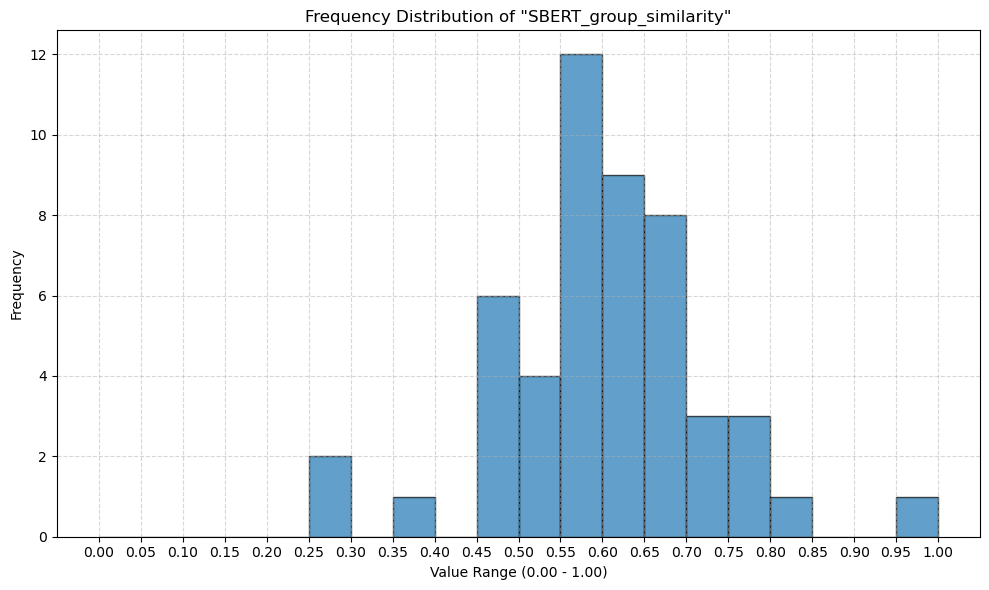

In [22]:
plot_frequency_distribution(df_2,'SBERT_group_similarity')